In [2]:
!pip install -q "kagglehub[pandas-datasets]"

import kagglehub
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Download the dataset using KaggleHub
dataset_path = kagglehub.dataset_download(
    "ziya07/network-traffic-anomaly-detection-dataset"
)

# Inspect available files
print("Dataset directory:", dataset_path)

for file in Path(dataset_path).rglob("*"):
    if file.is_file():
        print(file.name)

csv_files = list(Path(dataset_path).rglob("*.csv"))

if len(csv_files) != 1:
    print("CSV files found:")
    for file in csv_files:
        print(file)
else:
    df = pd.read_csv(csv_files[0])

    print("Dataset shape:", df.shape)
    print("Columns:", df.columns.tolist())
    display(df.head())

Using Colab cache for faster access to the 'network-traffic-anomaly-detection-dataset' dataset.
Dataset directory: /kaggle/input/network-traffic-anomaly-detection-dataset
embedded_system_network_security_dataset.csv
Dataset shape: (1000, 18)
Columns: ['packet_size', 'inter_arrival_time', 'src_port', 'dst_port', 'packet_count_5s', 'mean_packet_size', 'spectral_entropy', 'frequency_band_energy', 'label', 'protocol_type_TCP', 'protocol_type_UDP', 'src_ip_192.168.1.2', 'src_ip_192.168.1.3', 'dst_ip_192.168.1.5', 'dst_ip_192.168.1.6', 'tcp_flags_FIN', 'tcp_flags_SYN', 'tcp_flags_SYN-ACK']


,packet_size,inter_arrival_time,src_port,dst_port,packet_count_5s,mean_packet_size,spectral_entropy,frequency_band_energy,label,protocol_type_TCP,protocol_type_UDP,src_ip_192.168.1.2,src_ip_192.168.1.3,dst_ip_192.168.1.5,dst_ip_192.168.1.6,tcp_flags_FIN,tcp_flags_SYN,tcp_flags_SYN-ACK
0,0.405154,0.620362,62569,443,0.857143,0.0,0.834066,0.534891,0.0,False,True,True,False,False,False,False,False,False
1,0.527559,0.741288,59382,443,0.785714,0.0,0.147196,0.990757,0.0,False,True,False,False,False,True,False,True,False
2,0.226199,0.485116,65484,80,0.285714,0.0,0.855192,0.031781,0.0,False,True,False,False,True,False,False,False,False
3,0.573372,0.450965,51707,53,0.142857,0.0,0.153220,0.169958,0.0,False,False,False,True,False,False,False,False,False
4,0.651396,0.888740,26915,53,0.714286,0.0,0.923916,0.552053,0.0,True,False,False,True,False,False,False,True,False


In [3]:
df.head()

,packet_size,inter_arrival_time,src_port,dst_port,packet_count_5s,mean_packet_size,spectral_entropy,frequency_band_energy,label,protocol_type_TCP,protocol_type_UDP,src_ip_192.168.1.2,src_ip_192.168.1.3,dst_ip_192.168.1.5,dst_ip_192.168.1.6,tcp_flags_FIN,tcp_flags_SYN,tcp_flags_SYN-ACK
0,0.405154,0.620362,62569,443,0.857143,0.0,0.834066,0.534891,0.0,False,True,True,False,False,False,False,False,False
1,0.527559,0.741288,59382,443,0.785714,0.0,0.147196,0.990757,0.0,False,True,False,False,False,True,False,True,False
2,0.226199,0.485116,65484,80,0.285714,0.0,0.855192,0.031781,0.0,False,True,False,False,True,False,False,False,False
3,0.573372,0.450965,51707,53,0.142857,0.0,0.153220,0.169958,0.0,False,False,False,True,False,False,False,False,False
4,0.651396,0.888740,26915,53,0.714286,0.0,0.923916,0.552053,0.0,True,False,False,True,False,False,False,True,False


In [4]:
print(f"Shape: {df.shape}\n")
print(f"Dtype: \n{df.dtypes}\n")
print(f"Total Null values: {df.isnull().sum().sum()}")
print(f"Duplicates: {df.duplicated().sum()}")

# Zero Null and Duplicate values

Shape: (1000, 18)

Dtype: 
packet_size              float64
inter_arrival_time       float64
src_port                   int64
dst_port                   int64
packet_count_5s          float64
mean_packet_size         float64
spectral_entropy         float64
frequency_band_energy    float64
label                    float64
protocol_type_TCP           bool
protocol_type_UDP           bool
src_ip_192.168.1.2          bool
src_ip_192.168.1.3          bool
dst_ip_192.168.1.5          bool
dst_ip_192.168.1.6          bool
tcp_flags_FIN               bool
tcp_flags_SYN               bool
tcp_flags_SYN-ACK           bool
dtype: object

Total Null values: 0
Duplicates: 0


In [5]:
# Inspect the target variable

print("Unique Labels:",df['label'].unique())
print("\nLabel Counts:",df['label'].value_counts())

print("\nClass Percentages:")
print((df['label'].value_counts(normalize=True).sort_index()*100).round(2))

Unique Labels: [0. 1.]

Label Counts: label
0.0    900
1.0    100
Name: count, dtype: int64

Class Percentages:
label
0.0    90.0
1.0    10.0
Name: proportion, dtype: float64


### Target Variable Analysis

The dataset contains 1,000 observations and a binary target variable, `label`.

- **Label 0:** 900 observations (90%), representing normal network traffic.
- **Label 1:** 100 observations (10%), representing malicious network traffic.

The target distribution exhibits a 9:1 imbalance between normal and malicious traffic. Consequently, accuracy alone may provide a misleading assessment of model performance. Precision, recall, F1-score, and the confusion matrix will also be used during model evaluation.

Class imbalance will be considered during model development. Any resampling or class-weighting strategy will be applied only to the training data and evaluated against an untouched test set.

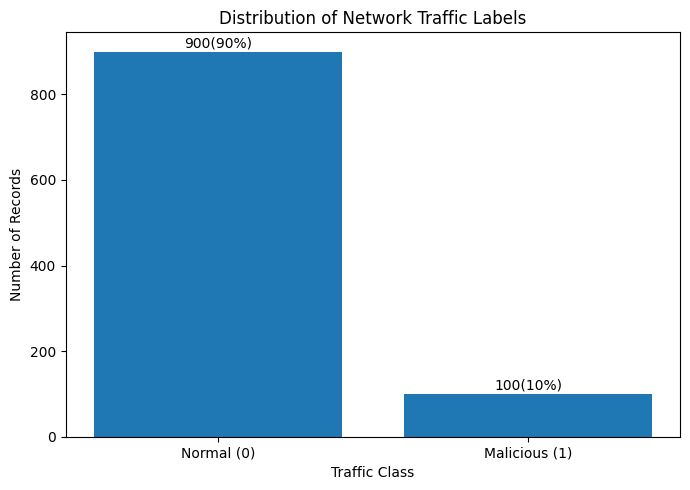

In [6]:
plt.figure(figsize=(7,5))
plt.bar([0,1],df['label'].value_counts())
plt.title("Distribution of Network Traffic Labels")
plt.xlabel("Traffic Class")
plt.ylabel("Number of Records")
plt.xticks([0,1],['Normal (0)','Malicious (1)'])


for i,count in enumerate(df['label'].value_counts().values):
  plt.text(i,count+10,f"{count}({count/len(df):.0%})",ha='center')

plt.tight_layout()
plt.show()

In [7]:
df['label'].value_counts().values

array([900, 100])

In [8]:
# Summary statistics for numerical columns
display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
packet_size,1000.0,0.502446,0.289606,0.0,0.256263,0.499642,0.741410,1.0
inter_arrival_time,1000.0,0.512259,0.281130,0.0,0.275909,0.515971,0.746523,1.0
src_port,1000.0,32024.617000,18520.890349,1038.0,16245.250000,31883.000000,47746.250000,65484.0
dst_port,1000.0,199.769000,180.078488,53.0,53.000000,80.000000,443.000000,443.0
packet_count_5s,1000.0,0.506857,0.303271,0.0,0.267857,0.500000,0.785714,1.0
mean_packet_size,1000.0,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.0
spectral_entropy,1000.0,0.495222,0.292927,0.0,0.236912,0.504290,0.761556,1.0
frequency_band_energy,1000.0,0.485651,0.295953,0.0,0.228039,0.467905,0.750876,1.0
label,1000.0,0.100000,0.300150,0.0,0.000000,0.000000,0.000000,1.0


In [9]:
print(df['dst_port'].value_counts())
print()
print(df['mean_packet_size'].value_counts())

dst_port
443    353
80     337
53     310
Name: count, dtype: int64

mean_packet_size
0.0    1000
Name: count, dtype: int64


- `dst_port` has only three values
- `mean_packet_size` has zero variance: All the values are zero

In [10]:
print("Unique values per columns:\n")
print(df.nunique().sort_values())

print("\nSource port range:", df["src_port"].min(), "-", df["src_port"].max())
print("Destination port range:", df["dst_port"].min(), "-", df["dst_port"].max())

Unique values per columns:

mean_packet_size            1
dst_ip_192.168.1.6          2
dst_ip_192.168.1.5          2
src_ip_192.168.1.3          2
src_ip_192.168.1.2          2
protocol_type_UDP           2
protocol_type_TCP           2
label                       2
tcp_flags_FIN               2
tcp_flags_SYN               2
tcp_flags_SYN-ACK           2
dst_port                    3
packet_count_5s            15
packet_size               698
src_port                  995
frequency_band_energy    1000
spectral_entropy         1000
inter_arrival_time       1000
dtype: int64

Source port range: 1038 - 65484
Destination port range: 53 - 443


In [11]:
numeric_features = df.select_dtypes(include=['int64','float64']).columns.values

display(df.groupby('label')[numeric_features].agg(['mean','median','std']))

packet_size                     inter_arrival_time                      \
             mean    median       std               mean    median       std   
label                                                                          
0.0      0.502605  0.498926  0.286879           0.516554  0.524684  0.281142   
1.0      0.501016  0.521117  0.314631           0.473604  0.460785  0.279453   

       src_port                        dst_port  ... mean_packet_size  \
           mean   median           std     mean  ...              std   
label                                            ...                    
0.0    32084.60  31856.0  18632.327226   201.13  ...              0.0   
1.0    31484.77  32062.0  17566.003054   187.52  ...              0.0   

      spectral_entropy                     frequency_band_energy            \
                  mean    median       std                  mean    median   
label                                                                        
0.0           0.497122  0.507569  0.294117              0.488141  0.472898   
1.0           0.478122  0.447323  0.282843              0.463242  0.424896   

                label              
            std  mean median  std  
label                              
0.0    0.295898   0.0    0.0  0.0  
1.0    0.296995   1.0    1.0  0.0  

[2 rows x 27 columns]

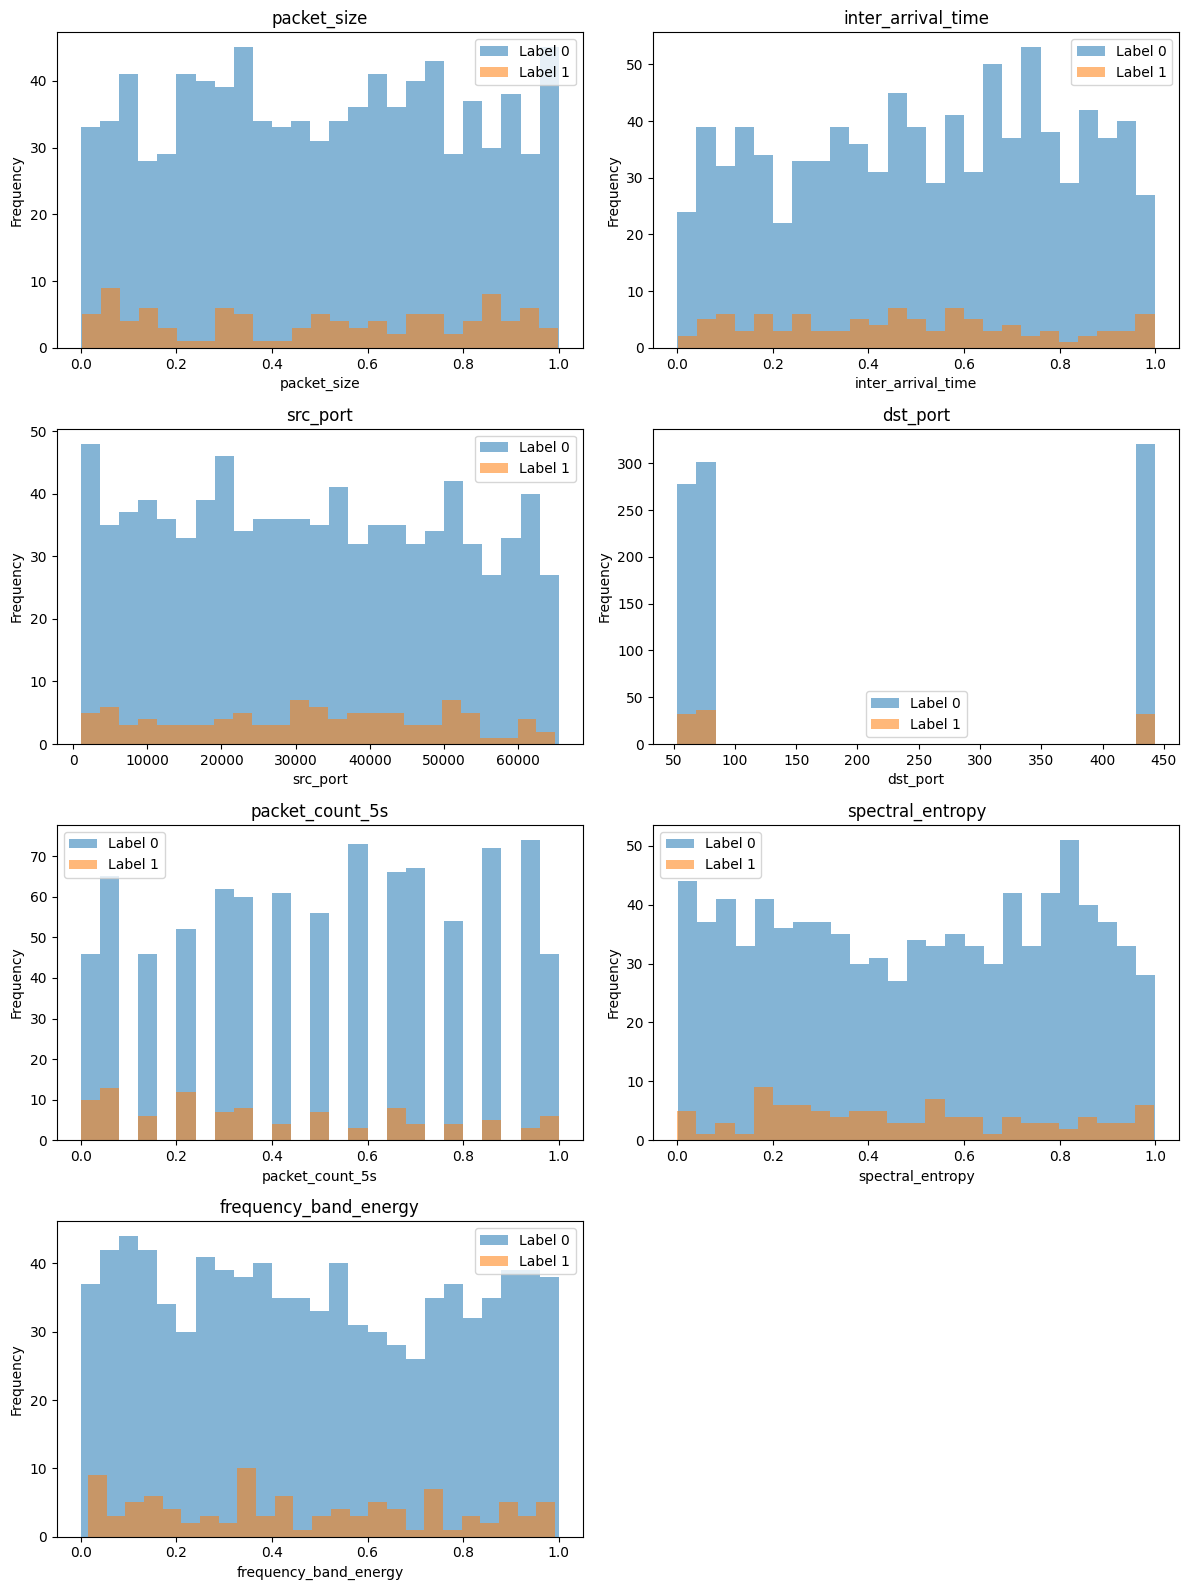

In [12]:
import matplotlib.pyplot as plt

features_to_plot = [
    "packet_size",
    "inter_arrival_time",
    "src_port",
    "dst_port",
    "packet_count_5s",
    "spectral_entropy",
    "frequency_band_energy",
]


fig,axes = plt.subplots(4,2,figsize=(12,16))
axes = axes.flatten()

for i,feature in enumerate(features_to_plot):
  # axes[i].hist(df[feature])
  # print(i,feature)
  for label,group in df.groupby('label'):
    axes[i].hist(group[feature],bins=25,alpha=0.55,label=f"Label {int(label)}")

  axes[i].set_title(feature)
  axes[i].set_xlabel(feature)
  axes[i].set_ylabel("Frequency")
  axes[i].legend()

axes[-1].axis("off")
plt.tight_layout()
plt.show()

- `packet_size` both classes cover nearly the entire 0-1 range. There is no obvious separation.
- `inter_arrival_time`, `src_port`, `spectral_entropy` and `frequency_band_energy`: both classes here also cover nearly entire range.
- `dst_port` are concentrated at three ports: *53, 80* and *443*. This is a discrete feature, so count or proportion chart would be more informative than a histogram

- `packet_count_5s` There are only 15 unique values, even though the feature is called a packet count and ranges fromm 0 to 1



---



 To compare the shapes of the distributions more fairly, normalize each class's histogram independently.



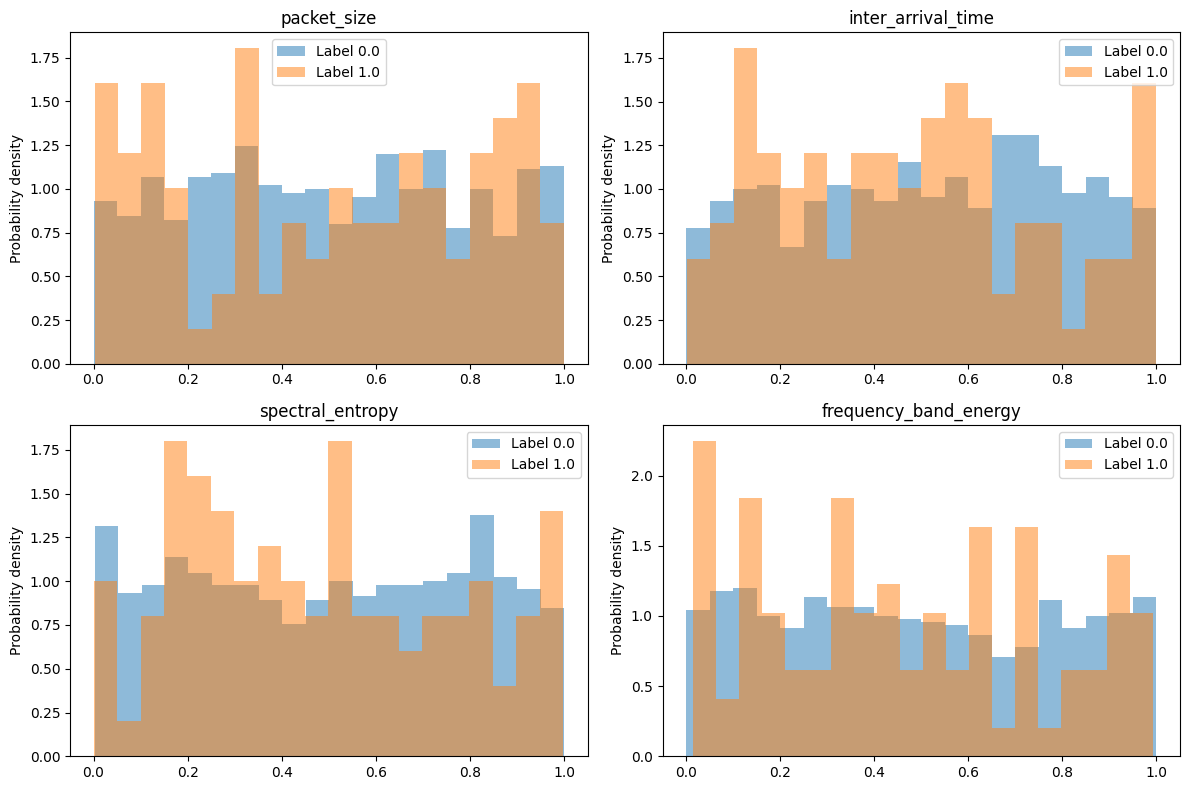

In [13]:
import matplotlib.pyplot as plt

features = [
    "packet_size",
    "inter_arrival_time",
    "spectral_entropy",
    "frequency_band_energy",
]

fig, axes = plt.subplots(2,2,figsize=(12,8))

for ax,feature in zip(axes.flat,features):
  for label,group in df.groupby('label'):
    ax.hist(group[feature],bins=20,density=True,alpha=0.5,label=f"Label {label}")
    ax.set_title(feature)
    ax.set_ylabel("Probability density")
    ax.legend()

plt.tight_layout()
plt.show()

In [14]:

port_analysis = df.groupby('dst_port')['label'].agg(
    total_records='count',
    malicious_records='sum',
    malicious_rate='mean'
)

port_analysis['malicious_rate'] *= 100
display(port_analysis.round(2))

,total_records,malicious_records,malicious_rate
dst_port,,,
53,310,32.0,10.32
80,337,36.0,10.68
443,353,32.0,9.07


- The table does not provide strong evidence that destination port alone is a useful predictor of malicious traffic.

In [15]:
from scipy.stats import chi2_contingency

# Contingency table: destination port versus traffic label
contingency = pd.crosstab(df["dst_port"], df["label"])

chi2, p_value, dof, expected = chi2_contingency(contingency)

print("Contingency table:")
display(contingency)

print(f"Chi-square statistic: {chi2:.4f}")
print(f"Degrees of freedom: {dof}")
print(f"P-value: {p_value:.4f}")

Contingency table:


label,0.0,1.0
dst_port,,
53,278,32
80,301,36
443,321,32


Chi-square statistic: 0.5530
Degrees of freedom: 2
P-value: 0.7584


**Port vs. Traffic Label: Chi-Square Test**

- Ho (Null Hypothesis): Destination port and traffic label are independent

- H1 (Alternative Hypothesis): Destination port and traffic label are associated

- `p value: 0.75`, `α: 0.05`, 0.75 > 0.05 we accept null hypothesis

- We don't find statistically significant evidence of an association between destination port and the traffic label.

---

## Investigating Boolean features against the traffic label.

In [16]:
binary_features = df.select_dtypes(include='bool').columns.tolist()
print("Number of Boolean features:",len(binary_features))
display(binary_features)


Number of Boolean features: 9


['protocol_type_TCP',
 'protocol_type_UDP',
 'src_ip_192.168.1.2',
 'src_ip_192.168.1.3',
 'dst_ip_192.168.1.5',
 'dst_ip_192.168.1.6',
 'tcp_flags_FIN',
 'tcp_flags_SYN',
 'tcp_flags_SYN-ACK']

In [17]:
for feature in binary_features:
  print(f"\n{'='*50}")
  print(f"Feature: {feature}")

  print("\nRecord counts:")
  display(pd.crosstab(df[feature],df['label']))

  print("\nProportion within each feature value:")
  display(pd.crosstab(df[feature],df['label'],normalize='index').round(3)*100)



Feature: protocol_type_TCP

Record counts:


label,0.0,1.0
protocol_type_TCP,,
False,621,68
True,279,32



Proportion within each feature value:


label,0.0,1.0
protocol_type_TCP,,
False,90.1,9.9
True,89.7,10.3



Feature: protocol_type_UDP

Record counts:


...

label,0.0,1.0
tcp_flags_SYN,,
False,89.4,10.6
True,91.9,8.1



Feature: tcp_flags_SYN-ACK

Record counts:


label,0.0,1.0
tcp_flags_SYN-ACK,,
False,673,72
True,227,28



Proportion within each feature value:


label,0.0,1.0
tcp_flags_SYN-ACK,,
False,90.3,9.7
True,89.0,11.0


- `src_ip_192.168.1.2` and `tcp_flags_SYN` has lower observed malicious rates when their values were True.

- `src_ip_192.168.1.3`, `dst_ip_192.168.1.5` and `tcp_flags_SYN-ACK` had somewhat higher observed malicious rates when their values were True.

- The differences are descriptive and have not yet been tested for statistical significance.

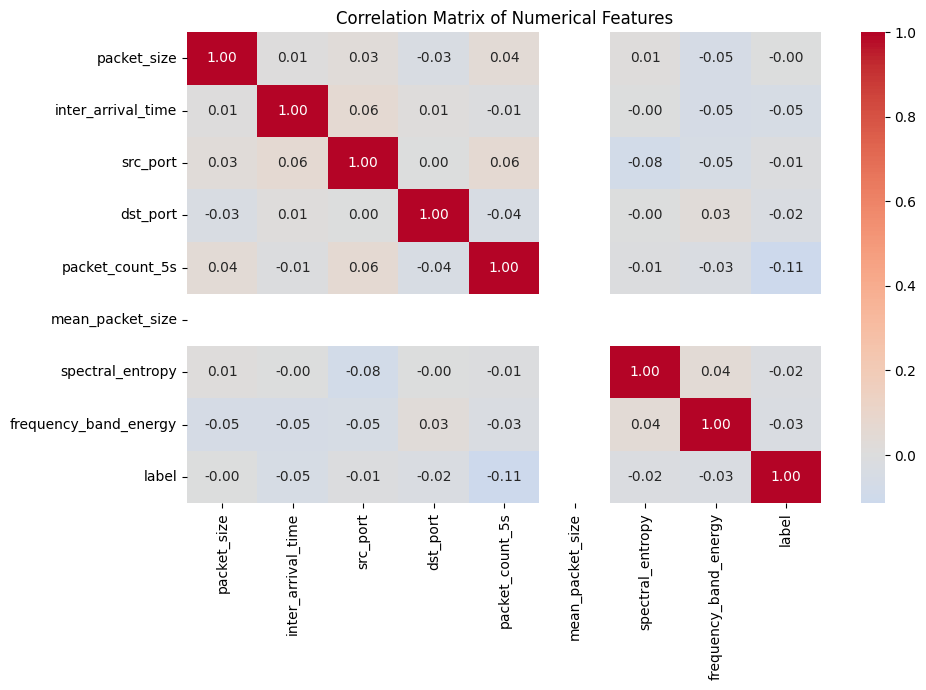

In [18]:
import seaborn as sns

plt.figure(figsize=(10,7))
sns.heatmap(df[numeric_features].corr(),annot=True,cmap='coolwarm',center=0,fmt=".2f")

plt.title('Correlation Matrix of Numerical Features')
plt.tight_layout()
plt.show()

- `mean_packet_size` has an undefined correlation because it is constant at zero.
- Most feature pairs also show weak linear correlations with one another.
---

**Conclusion**

The correlation analysis does not reveal a strong linear relationship between any individual numerical feature and the traffic label.

## Feature dependencies and potential data leakage

In [26]:
# Exclude the target from feature checks

X = df.drop(columns='label')

constant_features = [col for col in X.columns if X[col].nunique(dropna=False) <= 1]

print(f"Constant features:",constant_features)


# Check exact duplicate feature columns

duplicate_pairs = []
columns = X.columns.tolist()

for i in range(len(columns)):
    for j in range(i + 1, len(columns)):
        if X[columns[i]].equals(X[columns[j]]):
            duplicate_pairs.append((columns[i], columns[j]))

print("\nExact duplicate feature pairs:",duplicate_pairs)

# Check highly correlated feature pairs

X_numeric = X.astype(float)
corr = X_numeric.corr().abs()

high_corr_pairs = []

for i in range(len(corr.columns)):
  for j in range(i+1,len(corr.columns)):
    value = corr.iloc[i,j]
    if pd.notna(value) and value >= 0.90:
      high_corr_pairs.append((corr.columns[i],corr.columns[j],round(value,3)))

print("\nFeature pairs with absolute correlation >= 0.90:")
print(high_corr_pairs if high_corr_pairs else "None found")

Constant features: ['mean_packet_size']

Exact duplicate feature pairs: []

Feature pairs with absolute correlation >= 0.90:
None found


- `mean_packet_size` is the only constant feature.
- No  exact duplicate feature pairs were identified.
- No feature pairs had  Higher Linear absolute Pearson correlation of 0.90 or greater.